<img src='http://drive.google.com/uc?export=view&id=1UAsSD6z0wK4UJjjzBhDEIlSZnELLmeeb'>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# <font color='lightblue'>Answering Questions</font>

In this project you will use all you learnt about in the class to answer a question. Imagine you are part of a team and you have been assigned a question to answer, build a notebook that you would be able to share with your team that shows what you found.

In this project you will:

1.  Introduce your question of interest
2.  Make sure your reader knows enough about the data
3.  Wrangle and preprocess your data so that a team mate can reproduce your work
4.  Build and test a model that can provide insight into your question
5.  Interpret your model results
6.  Answer your question



Note: Marks will be awarded for clarity, organization, and succinctness. I.e., try to point out only the important parts in a well-organized easy to follow manner. (Marks: 3)

## <font color='lightblue'>1. Ask a question </font>

**Q1**: Layout your question of interest. Remember to state your question as clearly and simply as you can (Mark 1), and what your ideal outcome would be (Marks 1).


Can we make a model that can predict shipping cost on orders for a E-commerce store, ideally we can make a robust model that can accurately and precisely predict shipping price with minimal overfitting/underfitting and is the amount of days delivery takes important in the prediction of shipping cost?


**Q2**: Identify and describe what data sources you'll use (Marks 1). Make sure to talk about one of the following: data accuracy, reliability, validity, or sample selection. (Marks: 1)

We used a syntheticlly generated Kaggle dataset that has over 100,000 customer transaction.

Because of the synthetic nature of the data generation there is no good method to validate the data accruacy, reliablility or validity.

**Q3**: Layout what kind of ML problem you are facing and what kind of model you'll use to answer it (eg., is it unsupervised or supervised learning, and is it classification or regression). Make sure to say why. (Marks 1)

We are facing a regression machine learning model, we are trying to predict a continouse numerical variable. We will be using supervised learning with a linear regression model, we chose this because our data has labels and we belive a line of best fit to predict a continouse numerical variable will be the best method to get accurate predictions.




## <font color='lightblue'>2. Data understanding, exploration, and visualization </font>

**Action**: While above you gave an overview of the dataset(s) that will be used, here make sure that the reader understands the important details of the data. E.g., show a figure or descriptive statistic and explain why the reader should know about this, i.e., how will it help your reader understand your analysis? (Marks: 2)

In [ ]:
#Import libraries
import pathlib as path
import numpy as np
import pandas as pd
import random as rand
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn import cluster
import hdbscan as hd

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.sparse import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.datasets import fetch_openml
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

#Read the data to csv
customers = pd.read_csv("/content/customer_master-selected-columns.csv")
orders = pd.read_csv("/content/order_items.csv")
sales = pd.read_csv("/content/ecommerce_sales_customer_analytics_150k.csv")
products = pd.read_csv("/content/product_catalog.csv")

In [ ]:
# Merge relivent tables
#Combining orders table and product table
orders_prods= orders.merge(
products.drop(columns=['product_cost']),
on=['product_id','unit_price'],
how='inner'
)

#Merge the sales and orders_prods data and only keep features of interest
shipping = sales[[ 'order_id', 'customer_rating', 'customer_lifetime_value', 'estimated_delivery_days', 'delivery_days','customer_order_count']].merge(
    orders_prods[['order_id', 'quantity', 'profit', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost']],
    on='order_id',
    how='inner'
)

In [ ]:
shipping = shipping.dropna(how = 'any')

In [ ]:
shipping_df_clean = shipping.sample(100, random_state=42)

### The Data Types

In [ ]:
shipping_df_clean.dtypes

,0
order_id,object
customer_rating,float64
customer_lifetime_value,float64
estimated_delivery_days,float64
delivery_days,float64
customer_order_count,int64
quantity,int64
profit,float64
gross_sales,float64
discount_amount,float64




### Numerical
    estimated_delivery_days
    delivery_days
    quantity
    profit
    gross_sales
    discount_amount
    tax_amount
    shipping_cost
    net_sales
    product_cost
    customers_lifetime_value
    customer_rating
    customer_order_count

### Identifers
    order_id

### Summary Statistics and visualizations for Shipping Cost

In [ ]:
#Descriptive statistics on shippign cost
shipping_df_clean["shipping_cost"].describe()

,shipping_cost
count,100.000000
mean,7.809100
std,6.404509
min,0.000000
25%,3.122500
50%,5.800000
75%,12.175000
max,24.450000


In [ ]:
#Calculate the median shipping cost
median_ship = shipping_df_clean['shipping_cost'].median()

print(f"The medain cost of a shipment for all deliveries is {median_ship} $.")

The medain cost of a shipment for all deliveries is 5.800000000000001 $.


Based on the summary statistics provided, we can observe that the average shipping cost is $7.80, with a standard deviation of $6.40 and a median of $5.80.

The highest shipping cost recorded was $24.50.

While the lowest was $0.

This data gives us a clearer picture of the shipping cost distribution and the typical amount customers pay.  Since the standard deviation is nearly equal to the mean, we hypothesize a right-skewed distribution with significant variation in shipping costs. This analysis helps us address the question of whether we can predict shipping costs in this store and understand the company’s shipping cost structure.

Text(0.5, 1.0, 'Shipping Cost vs Delivery Days')

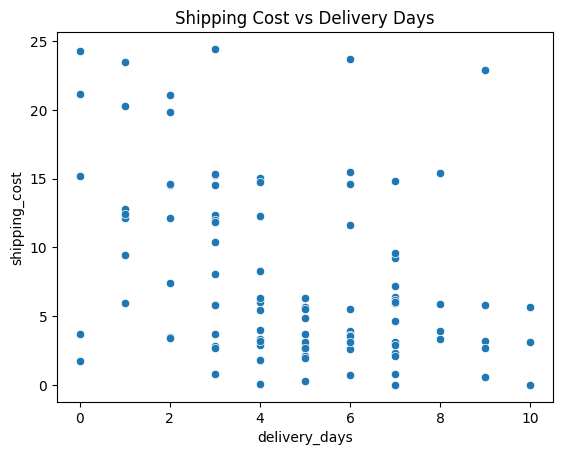

In [ ]:
sns.scatterplot(data=shipping_df_clean,
                x="delivery_days",
                y="shipping_cost")
plt.title('Shipping Cost vs Delivery Days',fontsize = 12)

We can see in the scatterplot that there's many different shipping costs for the same value of delivery days and there doesn't appear to be any kind of pattern.  What this shows us is that there is no relationship between shipping cost and delivery days.

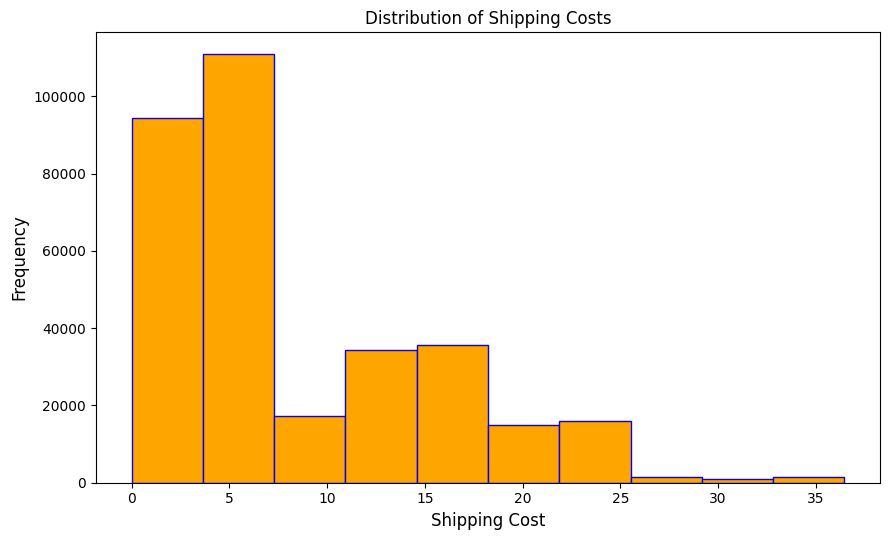

In [ ]:
# Distribution of shipping cost
#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a histogram of shipping cost and frequency
plt.hist(
    shipping['shipping_cost'],
    edgecolor = 'blue',
    color = 'orange')

#Add labels
plt.xlabel('Shipping Cost',fontsize = 12)
plt.ylabel('Frequency',fontsize = 12)
plt.title('Distribution of Shipping Costs',fontsize = 12)

plt.tight_layout()
plt.show()

Based on the visualization above one can see the right skew distribution of shipping cost, meaning cheaper shipping is more common than expensive shippign at this company. Shipping at this company will most commonly cost around 0 - 6 dollars

Supporting this visualization is the summary statisitcs, where on average shipping cost is 8.40 dollars and the median is 5.87 dollars.

Why should the reader care:

This gives the reader an idea of how much shipping should cost when ordering from this websight.





Text(0.5, 1.0, 'Shipping Cost vs Net Sales')

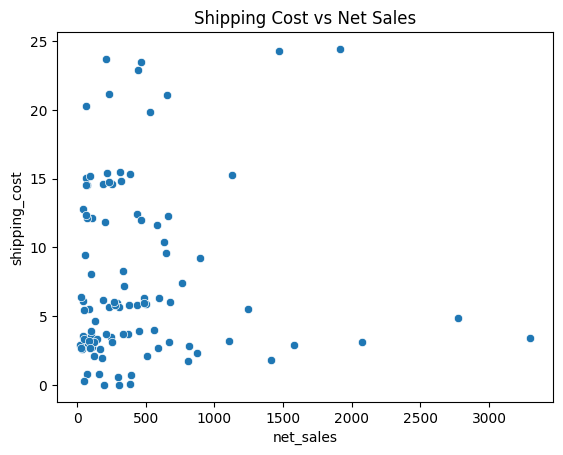

In [ ]:
sns.scatterplot(data=shipping_df_clean,
                x="net_sales",
                y="shipping_cost")
plt.title('Shipping Cost vs Net Sales',fontsize = 12)

Based on the scatter plot between just net sales and shipping cost, one would infer that there isn't a relationship between the two.  We can see that the vast majority of the data points are at the lower end of net sales and most data points are at the lower end of shipping cost.  However, again we don't see any sort of relationship.

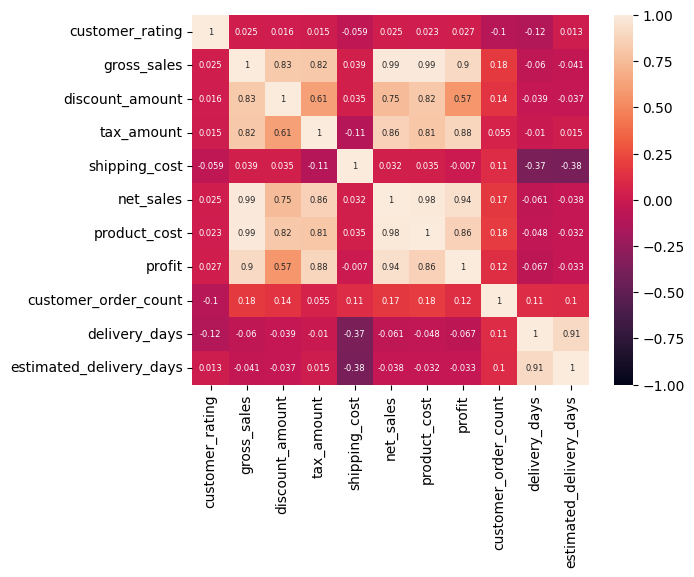

In [ ]:
shipping_corr = shipping_df_clean[['customer_rating','gross_sales',	'discount_amount',	'tax_amount',	'shipping_cost',	'net_sales',	'product_cost',	'profit', 'customer_order_count', 'delivery_days','estimated_delivery_days']].corr().round(3)
sns.heatmap(shipping_corr, annot=True, vmin=-1, vmax=1,
            annot_kws={"size": 6})
plt.show()

We can see shipping cost doesn't seem significantly correlated with anything. There is a small negative correlation between shipping costs and delivery days / estimated delivery days but that is it. So when shipping cost goes up, delivery days tend to go down. We can also see that most of the other features that are used to calculate shipping cost are highly positively correlated with each other, besides delivery days, estimated delivery days, and customer rating. There's also the obvious highly positive correlation between delivery days and estimated delivery days.

## <font color='lightblue'>3. Data wrangling and preprocessing </font>

**Action**: Layout all your data wrangling and preprocessing steps so that a reader will understand why you took each step, and would be able to reproduce your steps. (Marks: 3)

In [ ]:
#drop order id
shipping_df_clean = shipping_df_clean.drop(columns=['order_id'])

Here we drop order id as it is not a usefull feature to predict shipping cost.

## <font color='lightblue'>4. Build and test a model</font>



**Action:** Use your training dataset to build a model with the goal addressing your question of interest. (Marks: 2)

In [ ]:
#Split the data into trainign and testing

#Drop the feature we are prediciting for X
X = shipping_df_clean.drop('shipping_cost',axis = 1)

#Store the predicitor feature in Y
y = shipping_df_clean['shipping_cost']

#Train the model on 80% of the data and test it on 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#Make a Linear Regression model
LR_shipping = LinearRegression()

LR_shipping.fit(X_train, y_train)

y_predict = LR_shipping.predict(X_test)

**Q4**: Measure the performance of your model, and describe how well your model generalizes to new data (Marks: 2)

## <font color='lightblue'>5. Interpret your model</font>

**Q5**: Interpret your model results. E.g., what features contributed to your predictions, if possible, can you determine the sign and magnitude of the effect (Marks: 2).

In [ ]:
#Get the R2 score
r2_score(y_test, y_predict)

1.0

With a R squared score of exactly 1.0, we have 100% of our variation in shipping cost explained by our linear regression model. This could be due to overfitting, but we will test whether or not we have an exact mathmatical calculation of shipping cost happening in our model.

In [ ]:
mean_absolute_error(y_test,y_predict)

1.2976732535752156e-13

On average our model's predicted shipping cost is off by essentially 0 dollars from the actual shipping cost. This indicates our model makes nearly perfect predictions on test data. This intuitively makes sense since our R squared is exactly 1.0.

In [ ]:
shipping_df_clean.corr(numeric_only=True)['shipping_cost'].sort_values()

,shipping_cost
estimated_delivery_days,-0.290932
delivery_days,-0.257004
tax_amount,-0.064597
customer_rating,-0.033755
discount_amount,-0.028267
customer_order_count,-0.022938
product_cost,-0.015002
gross_sales,-0.011062
customer_lifetime_value,-0.003426
profit,-0.002700


There does not seem to be any features that are 100% correlated with shipping cost so there is not one feature that explains 100% of the variation in the shipping cost.

In [ ]:
#Show the coefficent of the linear reggression model
coef_df = pd.DataFrame({
    'Features': X.columns,
    'Coefficent': LR_shipping.coef_ #Calculate coefficent
}).sort_values(by='Coefficent', ascending=False)

print(coef_df)

                   Features    Coefficent
10                net_sales  1.000000e+00
8           discount_amount  4.000000e-01
0           customer_rating  4.432950e-14
5                  quantity  3.959906e-14
4      customer_order_count  6.904019e-15
1   customer_lifetime_value  1.062518e-17
3             delivery_days -8.410190e-17
2   estimated_delivery_days -1.747581e-15
7               gross_sales -4.000000e-01
9                tax_amount -4.000000e-01
6                    profit -6.000000e-01
11             product_cost -6.000000e-01


Due to net sales coefficient being equal to 1 and our model R squared equaling 1, we can tell that shipping cost can be mathmatically reconstructed from net sales and some other features.

The linear regression coefficients for quantity, estimate_delivery_days, delivery_days,customer_lifetime_value, delivery_days, customer_rating, and customer_order_count are essentially negligible.  A change in any of those features will not effect the calculated shipping_cost value.  

The model uses net_sales, discount_amount, tax_amount, gross_sales, product_cost, and profit to calculate shipping_cost. When net_sales goes up by a value of 1 shipping_cost goes up by 1, when discount_amount goes up by 1 shipping_cost goes up by 0.4, when tax_amount goes up by 1 shipping_cost goes down by 0.4, when gross_sales goes up by 1 shipping_cost goes down by 0.4, when product_cost goes up by 1 shipping_cost goes down by 0.6, and when profit goes up by 1 shipping_cost goes down by 0.6

In [ ]:
#Get the permutation importance
importance = permutation_importance(LR_shipping,
                                    X_test,
                                    y_test,
                                    random_state=42)

#Store values in df
feature_importance = pd.DataFrame({
    'Features': X.columns,
    'Importance': importance.importances_mean
}).sort_values(by='Importance', ascending=False)



#Sort the df
feature_importance = feature_importance.sort_values(by='Importance',
                                                    ascending=False)

#Print the df
print(feature_importance)


                   Features    Importance
10                net_sales  15202.742766
7               gross_sales   3570.215195
11             product_cost   2686.481317
6                    profit    783.575767
8           discount_amount    389.201040
9                tax_amount     25.526169
1   customer_lifetime_value      0.000000
0           customer_rating      0.000000
3             delivery_days      0.000000
2   estimated_delivery_days      0.000000
4      customer_order_count      0.000000
5                  quantity      0.000000


From this we can see not only that net sales is relied on heavily to calculate shipping cost, but it shows us exactly which features are being used to calculate shipping cost directly and which features are not being used at all.
From this and our R squared of exactly 1.0 we can infer that there is a formula using some combination of the features net sales, gross sales, product cost, profit, discount amount, and tax amount to calculate shipping cost. While customer rating, estimated delivery days, customer lifetime value, customer order count, and quantity do not have any importance in the model.  Changing one of those features values will not effect the value of shipping cost.

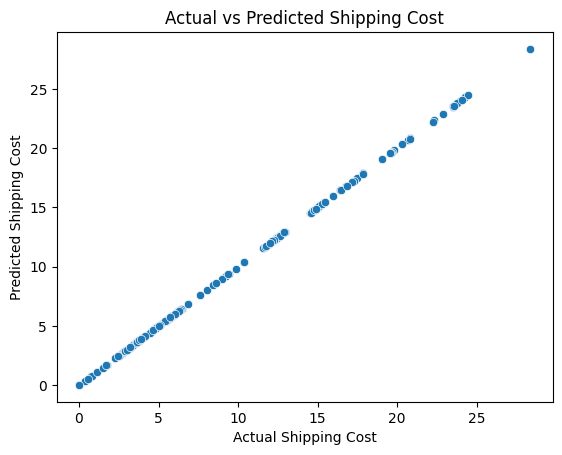

In [ ]:
sns.scatterplot(x=y_test, y=y_predict)

plt.xlabel("Actual Shipping Cost")
plt.ylabel("Predicted Shipping Cost")
plt.title("Actual vs Predicted Shipping Cost")

plt.show()

As we can see this graph supports our findings of our model having an R squared of exactly 1.0. There is a perfect straight line of all the predicted shipping cost vs the actual shipping cost

## We are going to make a model without net sales to see how it impacts the predictions of shippping cost

In [ ]:
#Set up X and y
shipping_df_temp = shipping_df_clean.drop(columns = ["net_sales"])
X_no_netsales = shipping_df_temp.drop(columns=['shipping_cost'], axis=1)
y_no_netsales = shipping_df_temp['shipping_cost']

#Train the model
X_train_no_netsales, X_test_no_netsales, y_train_no_netsales, y_test_no_netsales = train_test_split(X_no_netsales,
                                                                                                    y_no_netsales,
                                                                                                    test_size=0.2,
                                                                                                    random_state=42)
#Set up Linear Reggresion
LR_shipping_no_netsales = LinearRegression()
LR_shipping_no_netsales.fit(X_train_no_netsales, y_train_no_netsales)

#Predict
y_predict_no_netsales = LR_shipping_no_netsales.predict(X_test_no_netsales)

#Get the R2 score
r2_score(y_test_no_netsales, y_predict_no_netsales)

0.06505853359321212

With the lower R2 score in the above model that does not have net sales feature we can see how difficult it is to predict how much it will cost to ship a product without the model directly calculating it from net sales.

## <font color='lightblue'>6. Answer your question</font>

**Q6:** Use your analysis above to answer your question of interest. Did you achieve your desired outcome, and what might the next steps be? Remember to write as though you are writing to team mates working on the same/similar problem. (Marks: 3)


Note: It is ok if your analysis doesn't provide a strong answer, you can point out where it failed. If anything you can cross the approach you took off the list of possible ways to tackle your question. I.e., you still made progress!

We did succeed in creating a model to calculate shipping cost, however we did not achieve our desired outcome. Our created model mathematically uses a handful of features to directly calculate our feature of interest, shipping cost, and delivery days was not used in this calculation to get shipping cost when we suspected it would be important. This wasn't our desired outcome. We wanted to create a model that accurately predicts shipping cost but not one that perfectly calculates it. Our model however, even with its R squared value of 1.0 on test data, is not overfitting. If given new data, it will perfectly predict shipping cost due to the mathematical relationship. Our next step would be to create a new model with some of the features that are used to directly calculate shipping cost dropped. We started doing this by dropping net sales but our models performance dropped significantly so more altering of the model is required. What we essentially discovered was a model is not required for shipping cost as it can be simply mathematically calculated. A model is not always needed.